# Chapter 11: Matrix Calculus — Labs

**Book**: *Mathematics for AI and Machine Learning* · **Chapter 11** (`chapter11-matrix-calculus`)
**Requirements**: `numpy`, `torch`, `matplotlib`

The lecture solved the nine exercises. This notebook checks them in one cell and then runs ten labs, the experiments behind the chapter:

1. **Lab 1 — Exercise answers in one cell**: every exercise result confirmed numerically with `torch.func`.
2. **Lab 2 — Backpropagation by hand**: the chapter's SimpleDNN, one VJP per layer, against autograd; and what the textbook Jacobian chain would cost.
3. **Lab 3 — Forward vs reverse mode, timed**: `jacfwd` (JVPs) and `jacrev` (VJPs) as the input or the output grows.
4. **Lab 4 — Hessian-vector products**: an HVP as one JVP of the gradient, the sharpest curvature by power iteration, and Hessian-free Newton.
5. **Lab 5 — Fréchet adjoints, STE & Newton–Schulz**: the operator view, quantization gradients, and the Muon orthogonalizer.
6. **Lab 6 — Attention backward by hand**: the adjoints of Exercise 7 against autograd, and why FlashAttention rebuilds $P$ instead of storing it.
7. **Lab 7 — The score Jacobian and its trace**: Exercise 8's derivatives, and Hutchinson's estimator of the divergence from a few VJPs.
8. **Lab 8 — GPTQ**: quantization guided by the Hessian $H = 2X^\top X$ of Exercise 9, against round-to-nearest.
9. **Lab 9 — Gradient checking**: finite differences in single and double precision, and the complex step.
10. **Lab 10 — The memory bill of backpropagation**: activation checkpointing, peak memory against time.


In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
torch.set_default_dtype(torch.float64)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
print("NumPy version:", np.__version__)
print("PyTorch version:", torch.__version__)


NumPy version: 2.2.6
PyTorch version: 2.9.1+cu128


---
## Lab 1: Exercise Answers in One Cell

Each line compares a closed-form answer from the solutions with `torch.func` (`grad`, `jacrev`, `hessian`, `jvp`, `vjp`). Errors near $10^{-15}$ confirm the derivation; the lecture has the reasoning.


In [2]:
from torch.func import grad, jacrev, jacfwd, hessian, jvp, vjp

torch.manual_seed(0)
x = torch.randn(4)
A = torch.randn(4, 4); A = (A + A.T) / 2; b = torch.randn(4)
W, bb = torch.randn(3, 4), torch.randn(3)
Xd, yd, w = torch.randn(10, 4), torch.randn(10), torch.randn(4)
logistic = lambda w: torch.nn.functional.softplus(-yd.sign() * (Xd @ w)).sum()
d = torch.randn(4)
f6 = lambda x: torch.log(1 + torch.exp(x[0]) + torch.exp(x[1]))
Q, K, V = torch.randn(3, 6, 4).unbind(0); Ybar = torch.randn(6, 4)
P = torch.softmax(Q @ K.T / 2, dim=-1)
Wt, U, xt = torch.randn(4, 5), torch.randn(5, 4), torch.randn(4)
Xq, Dl = torch.randn(16, 4), torch.randn(4, 3)
y3 = torch.sigmoid(W @ x + bb)

checks = {
    "Ex 1  grad of x^T A x + b^T x = 2Ax + b": grad(lambda x: x @ A @ x + b @ x + 1.5)(x) - (2 * A @ x + b),
    "Ex 2  Jacobian of exp = diag(e^x)": jacrev(torch.exp)(x) - torch.diag(torch.exp(x)),
    "Ex 3  dy/dx = diag(y(1-y)) W": jacrev(lambda x: torch.sigmoid(W @ x + bb))(x) - torch.diag(y3 * (1 - y3)) @ W,
    "Ex 4  Hessian of LS loss = X^T X": hessian(lambda w: 0.5 * ((yd - Xd @ w) ** 2).sum())(w) - Xd.T @ Xd,
    "Ex 5  Hd = JVP of the gradient": jvp(grad(logistic), (w,), (d,))[1] - hessian(logistic)(w) @ d,
    "Ex 6  grad, Hessian at 0": torch.cat([grad(f6)(torch.zeros(2)) - 1 / 3,
                                           (hessian(f6)(torch.zeros(2)) - torch.tensor([[2., -1], [-1, 2]]) / 9).flatten()]),
    "Ex 7  dV = P^T Ybar": vjp(lambda V: P @ V, V)[1](Ybar)[0] - P.T @ Ybar,
    "Ex 8  ds/dx = W diag(1 - tanh^2) U": jacrev(lambda x: Wt @ torch.tanh(U @ x))(xt) - Wt @ torch.diag(1 - torch.tanh(U @ xt) ** 2) @ U,
    "Ex 9  grad of ||X Delta||^2 = 2 X^T X Delta": grad(lambda D: ((Xq @ D) ** 2).sum())(Dl) - 2 * Xq.T @ Xq @ Dl,
}
for name, err in checks.items():
    print(f"{name:44s} error {err.norm().item():.1e}")


Ex 1  grad of x^T A x + b^T x = 2Ax + b      error 0.0e+00
Ex 2  Jacobian of exp = diag(e^x)            error 0.0e+00
Ex 3  dy/dx = diag(y(1-y)) W                 error 0.0e+00
Ex 4  Hessian of LS loss = X^T X             error 1.5e-15
Ex 5  Hd = JVP of the gradient               error 4.6e-16
Ex 6  grad, Hessian at 0                     error 0.0e+00
Ex 7  dV = P^T Ybar                          error 0.0e+00
Ex 8  ds/dx = W diag(1 - tanh^2) U           error 4.9e-16
Ex 9  grad of ||X Delta||^2 = 2 X^T X Delta  error 1.9e-14


---
## Lab 2: Backpropagation by Hand on the SimpleDNN

The chapter's network: $\mathbf{z} = W_1\mathbf{x}$, $\mathbf{h} = \sigma(\mathbf{z})$, $\hat{\mathbf{y}} = W_2\mathbf{h}$, $\mathcal{L} = \frac{1}{2}\|\hat{\mathbf{y}} - \mathbf{y}\|^2$, here with MNIST-sized $N = 784$, $H = 256$, $M = 10$. The backward pass is one VJP per layer, using only $\mathbf{h}$ and $\mathbf{x}$ from the forward pass. The last lines compute what the textbook chain of Jacobians would need to store, at this size and at the chapter's Qwen2.5-7B MLP size, $N = 3584$, $H = 18944$.


In [3]:
torch.manual_seed(1)
N, H, M = 784, 256, 10
W1 = (torch.randn(H, N) / N**0.5).requires_grad_()
W2 = (torch.randn(M, H) / H**0.5).requires_grad_()
x, y = torch.randn(N), torch.randn(M)

# Forward pass, keeping only what the backward pass needs: x and h
z = W1 @ x
h = torch.sigmoid(z)
y_hat = W2 @ h
loss = 0.5 * ((y_hat - y) ** 2).sum()
loss.backward()

# Backward pass by hand: one VJP per layer, no Jacobian is formed
g_yhat = (y_hat - y).detach()
g_h = W2.detach().T @ g_yhat
g_z = g_h * h.detach() * (1 - h.detach())          # sigma'(z) from h, z not needed
g_W2 = torch.outer(g_yhat, h.detach())
g_W1 = torch.outer(g_z, x)

print(f"||grad W1 (by hand) - autograd|| = {(g_W1 - W1.grad).norm():.1e}")
print(f"||grad W2 (by hand) - autograd|| = {(g_W2 - W2.grad).norm():.1e}")

def chain_bytes(N, H):                              # dz/dvec(W1) is H x HN, float32
    return H * H * N * 4
for (n, hh) in [(N, H), (3584, 18944)]:
    print(f"N={n:>9,}, H={hh:>6,}:  Jacobian dz/dvec(W1) {chain_bytes(n, hh)/1e9:12,.1f} GB"
          f"   vs gradient of W1 {hh*n*4/1e9:6.3f} GB")


||grad W1 (by hand) - autograd|| = 2.1e-15
||grad W2 (by hand) - autograd|| = 0.0e+00
N=      784, H=   256:  Jacobian dz/dvec(W1)          0.2 GB   vs gradient of W1  0.001 GB
N=    3,584, H=18,944:  Jacobian dz/dvec(W1)      5,144.8 GB   vs gradient of W1  0.272 GB


---
## Lab 3: Forward vs Reverse Mode, Timed

`jacfwd` builds a Jacobian from JVPs, one per input; `jacrev` from VJPs, one per output. For a two-layer map $\mathbb{R}^N \to \mathbb{R}^M$, the left panel grows the input with a single output (a loss), the right panel grows the output with four inputs (a small simulator). Each mode is cheap exactly when its count, $N$ or $M$, is small.


N = 4096, M = 1:  jacfwd / jacrev = 169.1x
N = 4, M = 4096:  jacrev / jacfwd =  87.3x


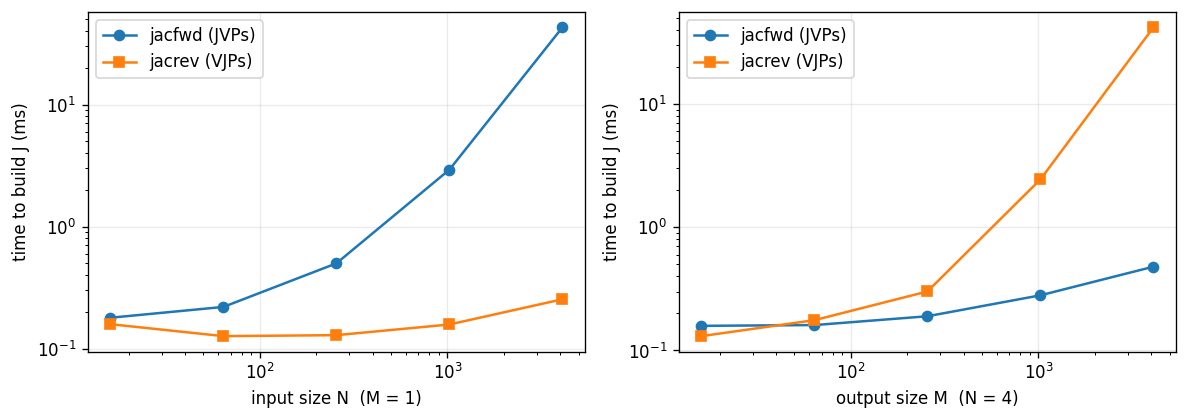

In [4]:
import time
torch.manual_seed(2)

def mlp(n_in, n_out, width=256):
    W_a, W_b = torch.randn(width, n_in) / n_in**0.5, torch.randn(n_out, width) / width**0.5
    return lambda x: W_b @ torch.tanh(W_a @ x)

def seconds(fn, x, reps=3):
    fn(x)                                            # warm-up
    t0 = time.perf_counter()
    for _ in range(reps):
        fn(x)
    return (time.perf_counter() - t0) / reps

sizes = [16, 64, 256, 1024, 4096]
grow_in = {"jacfwd": [], "jacrev": []}
grow_out = {"jacfwd": [], "jacrev": []}
for n in sizes:
    f = mlp(n, 1); x = torch.randn(n)
    grow_in["jacfwd"].append(seconds(jacfwd(f), x)); grow_in["jacrev"].append(seconds(jacrev(f), x))
    g = mlp(4, n); x4 = torch.randn(4)
    grow_out["jacfwd"].append(seconds(jacfwd(g), x4)); grow_out["jacrev"].append(seconds(jacrev(g), x4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, data, label in ((axes[0], grow_in, "input size N  (M = 1)"), (axes[1], grow_out, "output size M  (N = 4)")):
    ax.loglog(sizes, [1e3 * t for t in data["jacfwd"]], "o-", label="jacfwd (JVPs)")
    ax.loglog(sizes, [1e3 * t for t in data["jacrev"]], "s-", label="jacrev (VJPs)")
    ax.set_xlabel(label); ax.set_ylabel("time to build J (ms)"); ax.legend()
plt.tight_layout(); plt.savefig("../img/lab3_jvp_vjp_timing.png", dpi=200); plt.show()
print(f"N = 4096, M = 1:  jacfwd / jacrev = {grow_in['jacfwd'][-1] / grow_in['jacrev'][-1]:5.1f}x")
print(f"N = 4, M = 4096:  jacrev / jacfwd = {grow_out['jacrev'][-1] / grow_out['jacfwd'][-1]:5.1f}x")


---
## Lab 4: Hessian-Vector Products — Curvature Without the Hessian

For logistic regression with $N = 500$ weights, $H\mathbf{d}$ is computed as one JVP of the gradient (forward over reverse) and checked against the explicit Hessian. Power iteration on these products finds the largest eigenvalue, the sharpness of the loss; and conjugate gradient on them gives Hessian-free Newton steps, compared with gradient descent at the step size $1/\lambda_{\max}$. The feature scales span two orders of magnitude, as real features do, which makes the problem ill-conditioned.


||HVP - H d|| = 9.8e-16   (H has 250,000 entries, the HVP needs 500)
lambda_max: power iteration 0.273260   eigvalsh 0.273262   (condition number 7,520)
after 10 iterations: Newton-CG 0.0e+00   gradient descent 2.4e-01   (gradient descent after 200: 6.9e-02)


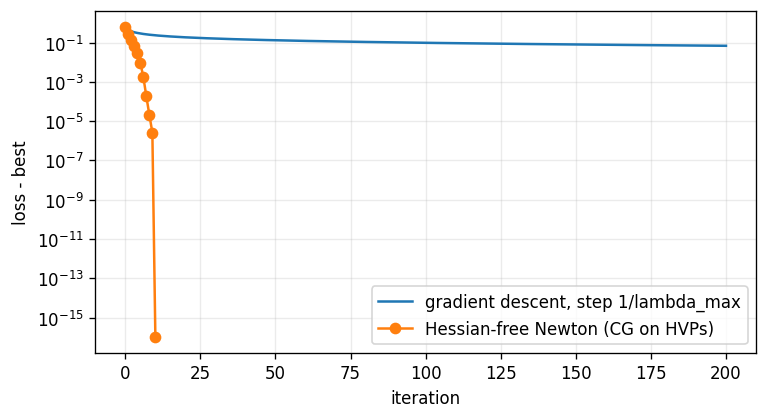

In [5]:
torch.manual_seed(3)
K_s, N_w = 2000, 500
Xl = torch.randn(K_s, N_w) * torch.logspace(0, -2, N_w)   # feature scales from 1 to 0.01: ill-conditioned
w_true = torch.randn(N_w)
yl = (Xl @ w_true + 0.5 * torch.randn(K_s)).sign()
L4 = lambda w: torch.nn.functional.softplus(-yl * (Xl @ w)).mean() + 1e-5 * (w @ w)
g4 = grad(L4)
hvp = lambda w, d: jvp(g4, (w,), (d,))[1]           # forward over reverse

w0, d = torch.zeros(N_w), torch.randn(N_w)
H4 = hessian(L4)(w0)
print(f"||HVP - H d|| = {(hvp(w0, d) - H4 @ d).norm():.1e}   (H has {N_w**2:,} entries, the HVP needs {N_w})")

# Largest eigenvalue (sharpness) by power iteration, using only HVPs
v = torch.randn(N_w)
for _ in range(100):
    v = hvp(w0, v); v = v / v.norm()
lam = v @ hvp(w0, v)
ev = torch.linalg.eigvalsh(H4)
print(f"lambda_max: power iteration {lam:.6f}   eigvalsh {ev[-1]:.6f}   (condition number {ev[-1] / ev[0]:,.0f})")

def newton_cg(w, iters=10, cg_steps=20):
    hist = [L4(w).item()]
    for _ in range(iters):
        g = g4(w); p = torch.zeros_like(w); r = -g.clone(); s = r.clone()
        for _ in range(cg_steps):                  # solve H p = -g with HVPs only
            Hs = hvp(w, s); a = (r @ r) / (s @ Hs)
            p, r_new = p + a * s, r - a * Hs
            if r_new.norm() < 1e-10: break
            s, r = r_new + (r_new @ r_new) / (r @ r) * s, r_new
        w = w + p; hist.append(L4(w).item())
    return hist

def grad_descent(w, iters=200, lr=1 / lam.item()):
    hist = [L4(w).item()]
    for _ in range(iters):
        w = w - lr * g4(w); hist.append(L4(w).item())
    return hist

h_newton, h_gd = newton_cg(torch.zeros(N_w)), grad_descent(torch.zeros(N_w))
best = min(h_newton + h_gd)
plt.figure(figsize=(6.5, 3.6))
plt.semilogy([v - best + 1e-16 for v in h_gd], label="gradient descent, step 1/lambda_max")
plt.semilogy([v - best + 1e-16 for v in h_newton], "o-", label="Hessian-free Newton (CG on HVPs)")
plt.xlabel("iteration"); plt.ylabel("loss - best"); plt.legend(); plt.tight_layout()
plt.savefig("../img/lab4_newton_vs_gd.png", dpi=200); plt.show()
print(f"after 10 iterations: Newton-CG {h_newton[10] - best:.1e}   gradient descent {h_gd[10] - best:.1e}"
      f"   (gradient descent after 200: {h_gd[200] - best:.1e})")


---
## Lab 5: Fréchet Adjoints, Straight-Through Estimator (STE) & Muon Newton-Schulz

### 1. Fréchet Derivative & The Adjoint Identity (§11.6 & §11.7)
For a matrix-to-matrix function $f: \mathbb{R}^{N\times N} \to \mathbb{R}^{N\times N}$, the Fréchet derivative $f'(X)[\Delta]$ maps an input perturbation $\Delta$ to the first-order change. For the matrix inverse $f(X) = X^{-1}$:
$$f'(X)[\Delta] = -X^{-1}\Delta X^{-1}.$$
When evaluating a scalar loss $\mathcal{L}$ with upstream adjoint $\bar{Y} = \nabla_Y\mathcal{L}$, the chain rule transports sensitivities backward via the **adjoint operator** $f'(X)^*$:
$$\langle \bar{Y}, f'(X)[\Delta] \rangle = \operatorname{tr}(\bar{Y}^\top (-X^{-1}\Delta X^{-1})) = \operatorname{tr}((-X^{-\top}\bar{Y}X^{-\top})^\top \Delta) = \langle f'(X)^*[\bar{Y}], \Delta \rangle.$$
Hence, the parameter gradient is:
$$\nabla_X\mathcal{L} = f'(X)^*[\bar{Y}] = -X^{-\top}\bar{Y}X^{-\top}.$$

### 2. Non-Differentiable Operations & Straight-Through Estimator (STE) (§11.5)
Quantization functions $Q(x) = \operatorname{round}(x)$ have zero derivative almost everywhere. The **Straight-Through Estimator (STE)** enables gradient propagation by defining:
$$\text{Forward: } \hat{x} = \operatorname{round}(x), \qquad \text{Backward: } \frac{\partial\mathcal{L}}{\partial x} \approx \frac{\partial\mathcal{L}}{\partial\hat{x}}.$$

### 3. Newton-Schulz Iteration for Polar Decomposition (Muon Optimizer Engine) (§11.8)
The polar decomposition factors any matrix $G \in \mathbb{R}^{M\times N}$ ($M \ge N$) into $G = QS$, where $Q$ has orthonormal columns ($Q^\top Q = I$) and $S$ is symmetric positive semidefinite. The **Muon optimizer** (Momentum Orthogonalized by Newton-Schulz) replaces Adam's diagonal scaling by projecting gradient matrices onto their polar factor $Q$.
Using the Taylor expansion $(I - E)^{-1/2} \approx I + \frac{1}{2}E$, the Newton-Schulz iteration computes $Q$ purely through **matrix multiplications**:
$$Q_{t+1} = \frac{1}{2}Q_t(3I - Q_t^\top Q_t), \qquad \text{initialized with } Q_0 = \frac{G}{\|G\|_2}.$$
It exhibits **quadratic convergence** to the exact polar factor $UV^\top$ (where $G = U\Sigma V^\top$), driving all singular values to 1:
$$s_{t+1} = \frac{1}{2}s_t(3 - s_t^2) \implies (1 - s_{t+1}) = \frac{1}{2}(1 - s_t)^2 (2 + s_t) = \mathcal{O}((1 - s_t)^2).$$

[Fréchet] ||f(X+Delta) - (X^-1 - X^-1 Delta X^-1)||_F  = 1.11e-06
[Adjoint] ||X.grad - (-X^-T Y_bar X^-T)||_F               = 2.32e-14
[Adjoint Identity] |<Y_bar, f'[Delta]> - <f'^*[Y_bar], Delta>| = 1.73e-18
[STE    ] Forward w_q = [ 1.  -0.5  3. ], grad = [0.  0.5 0. ] (non-zero pass-through!)
[Muon NS] Final Orthogonality error ||Q^T Q - I||_F       = 3.14e-12
[Muon NS] Agreement with SVD polar factor ||Q - UV^T||_F  = 1.57e-12


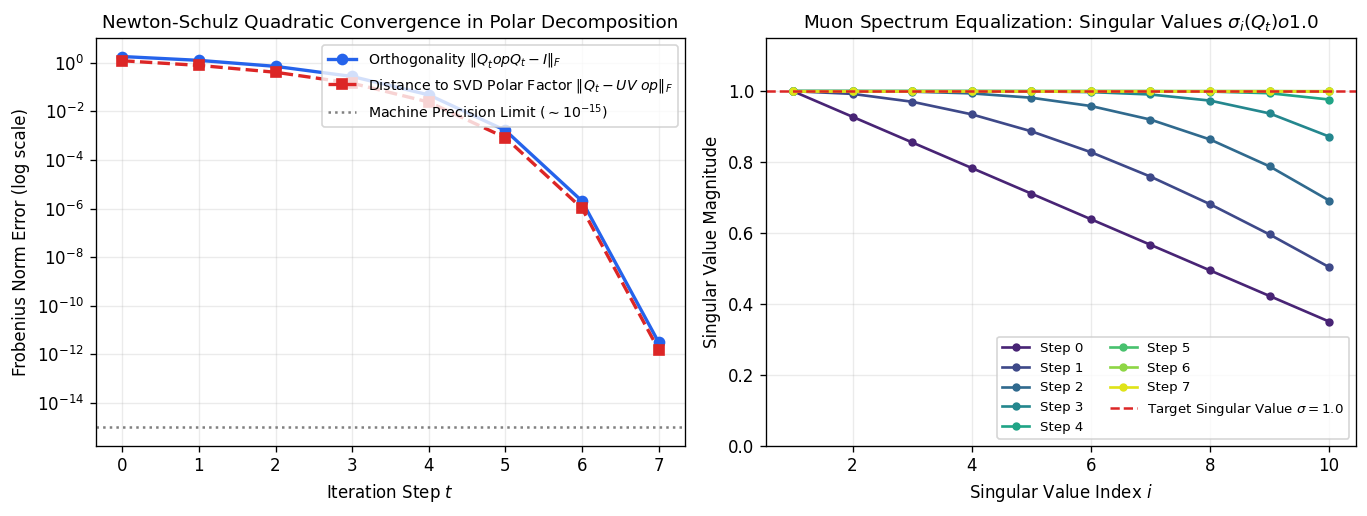

In [6]:
torch.manual_seed(42)

# ---------------------------------------------------------------------------
# 1. Fréchet Derivative & Adjoint Identity for Matrix Inverse: f(X) = X^{-1}
# ---------------------------------------------------------------------------
N_mat = 4
X_mat = torch.randn(N_mat, N_mat, requires_grad=True)
Delta_X = 1e-4 * torch.randn(N_mat, N_mat)
Y_bar_mat = torch.randn(N_mat, N_mat)

# Forward Fréchet derivative: f'(X)[Delta] = -X^{-1} Delta X^{-1}
X_inv = torch.linalg.inv(X_mat)
frechet_dir = -X_inv.detach() @ Delta_X @ X_inv.detach()

# Finite-difference verification of Fréchet derivative
f_diff = (torch.linalg.inv(X_mat.detach() + Delta_X) - X_inv.detach())
print(f"[Fréchet] ||f(X+Delta) - (X^-1 - X^-1 Delta X^-1)||_F  = {torch.norm(f_diff - frechet_dir).item():.2e}")

# Adjoint operator: f'(X)^*[Y_bar] = -X^{-T} Y_bar X^{-T}
grad_X_analytical = -X_inv.detach().T @ Y_bar_mat @ X_inv.detach().T
loss_mat = torch.sum(Y_bar_mat * torch.linalg.inv(X_mat))
loss_mat.backward()
print(f"[Adjoint] ||X.grad - (-X^-T Y_bar X^-T)||_F               = {torch.norm(X_mat.grad - grad_X_analytical).item():.2e}")

# Adjoint Identity verification: <Y_bar, f'(X)[Delta]> == <f'(X)^*[Y_bar], Delta>
lhs_adjoint = torch.sum(Y_bar_mat * frechet_dir)
rhs_adjoint = torch.sum(grad_X_analytical * Delta_X)
print(f"[Adjoint Identity] |<Y_bar, f'[Delta]> - <f'^*[Y_bar], Delta>| = {abs(lhs_adjoint - rhs_adjoint).item():.2e}")


# ---------------------------------------------------------------------------
# 2. Straight-Through Estimator (STE) Custom Autograd Operator
# ---------------------------------------------------------------------------
class STEQuantize(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, scale=4.0):
        ctx.scale = scale
        return torch.round(x * scale) / scale

    @staticmethod
    def backward(ctx, grad_output):
        # Pass gradient straight through unattenuated
        return grad_output, None

w_ste = torch.tensor([1.23, -0.67, 2.88], requires_grad=True)
target = torch.tensor([1.0, -1.0, 3.0])
w_q = STEQuantize.apply(w_ste, 2.0)
loss_ste = 0.5 * torch.sum((w_q - target) ** 2)
loss_ste.backward()
print(f"[STE    ] Forward w_q = {w_q.detach().numpy()}, grad = {w_ste.grad.numpy()} (non-zero pass-through!)")


# ---------------------------------------------------------------------------
# 3. Newton-Schulz Iteration for Polar Decomposition (Muon Engine)
# ---------------------------------------------------------------------------
N_dim = 10
# Generate matrix with singular values in [0.35, 1.0] (moderate condition number)
U_rand, _ = torch.linalg.qr(torch.randn(N_dim, N_dim))
V_rand, _ = torch.linalg.qr(torch.randn(N_dim, N_dim))
S_orig = torch.linspace(1.0, 0.35, N_dim)
G_mat = U_rand @ torch.diag(S_orig) @ V_rand.T

U_svd, S_svd, Vh_svd = torch.linalg.svd(G_mat)
Q_polar_svd = U_svd @ Vh_svd

Q_t = G_mat / S_svd[0].item()
I_N = torch.eye(N_dim)
ortho_errors = []
polar_errors = []
singular_hist = []
max_steps = 7

for step in range(max_steps + 1):
    err_ortho = torch.norm(Q_t.T @ Q_t - I_N, p="fro").item()
    err_polar = torch.norm(Q_t - Q_polar_svd, p="fro").item()
    s_vals = torch.linalg.svdvals(Q_t).numpy()
    ortho_errors.append(err_ortho)
    polar_errors.append(err_polar)
    singular_hist.append(s_vals)
    if step < max_steps:
        # Pure matrix multiplication update
        Q_t = 0.5 * Q_t @ (3.0 * I_N - Q_t.T @ Q_t)

print(f"[Muon NS] Final Orthogonality error ||Q^T Q - I||_F       = {ortho_errors[-1]:.2e}")
print(f"[Muon NS] Agreement with SVD polar factor ||Q - UV^T||_F  = {polar_errors[-1]:.2e}")

# Visualization: Newton-Schulz Quadratic Convergence & Spectrum Equalization
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

steps_arr = np.arange(len(ortho_errors))
axes[0].semilogy(steps_arr, ortho_errors, "o-", color="#2563eb", lw=2, markersize=6, label=r"Orthogonality $\|Q_t^	op Q_t - I\|_F$")
axes[0].semilogy(steps_arr, polar_errors, "s--", color="#dc2626", lw=2, markersize=6, label=r"Distance to SVD Polar Factor $\|Q_t - UV^	op\|_F$")
axes[0].axhline(1e-15, color="gray", ls=":", label=r"Machine Precision Limit ($\sim 10^{-15}$)")
axes[0].set_title("Newton-Schulz Quadratic Convergence in Polar Decomposition")
axes[0].set_xlabel("Iteration Step $t$")
axes[0].set_ylabel("Frobenius Norm Error (log scale)")
axes[0].set_xticks(steps_arr)
axes[0].legend(loc="upper right", fontsize=8.5)

colors = plt.cm.viridis(np.linspace(0.1, 0.95, len(singular_hist)))
for step, (s_vals, col) in enumerate(zip(singular_hist, colors)):
    axes[1].plot(range(1, N_dim + 1), s_vals, "o-", color=col, lw=1.6, markersize=4, label=f"Step {step}")

axes[1].axhline(1.0, color="#dc2626", ls="--", lw=1.5, label=r"Target Singular Value $\sigma=1.0$")
axes[1].set_title(r"Muon Spectrum Equalization: Singular Values $\sigma_i(Q_t) 	o 1.0$")
axes[1].set_xlabel("Singular Value Index $i$")
axes[1].set_ylabel("Singular Value Magnitude")
axes[1].set_ylim(0.0, 1.15)
axes[1].legend(loc="lower right", fontsize=8.0, ncol=2)

plt.tight_layout()
plt.show()

---
## Lab 6: Attention Backward by Hand (Exercise 7)

Scaled dot-product attention $Y = PV$, $P = \mathrm{softmax}(S)$ row-wise, $S = QK^\top/\sqrt{d_k}$. The adjoints from Exercise 7:
$$\bar V = P^\top \bar Y, \qquad \bar P = \bar Y V^\top, \qquad \bar S = P \odot \big(\bar P - (\bar P \odot P)\mathbf 1 \mathbf 1^\top\big), \qquad \bar Q = \tfrac{1}{\sqrt{d_k}}\bar S K, \qquad \bar K = \tfrac{1}{\sqrt{d_k}}\bar S^\top Q.$$
The backward pass needs $P$, an $N \times N$ matrix per head. FlashAttention stores only $\mathrm{logsumexp}$ of each row of $S$ and rebuilds $P = \exp(S - \mathrm{lse})$ from $Q$ and $K$ when it is needed.

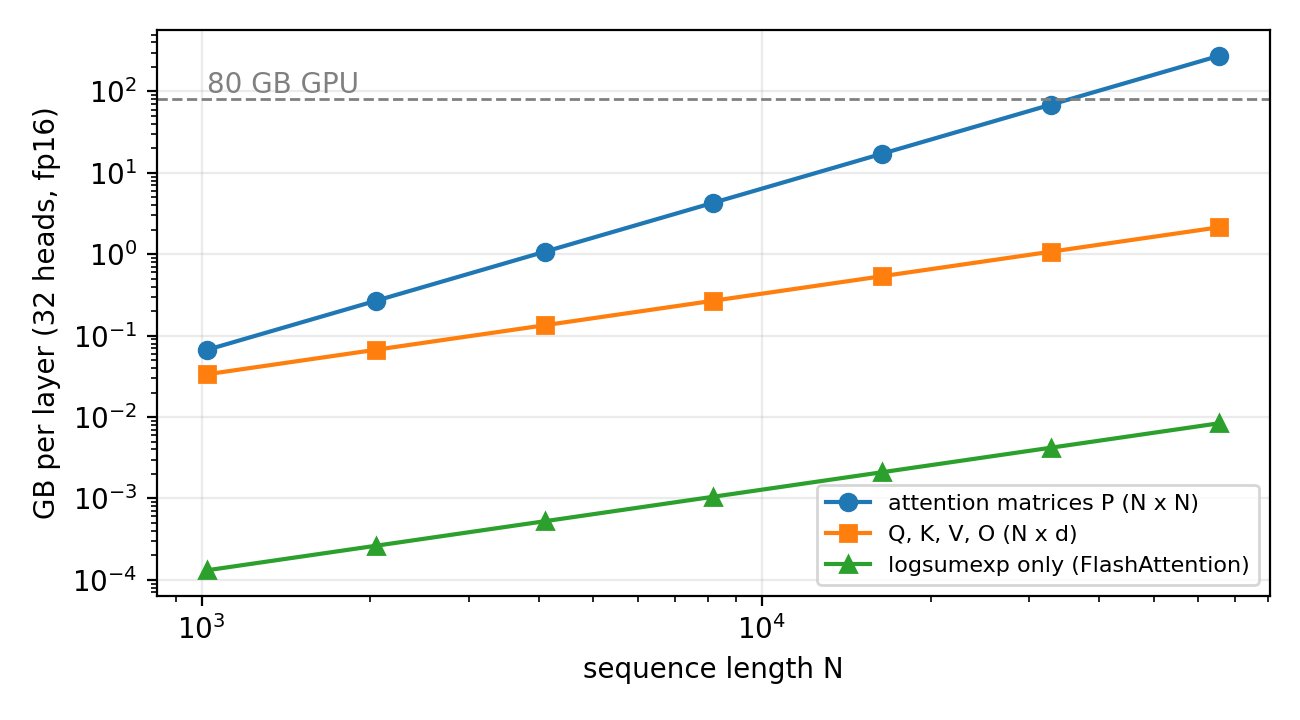

||V_bar (by hand) - autograd|| = 0.0e+00
||Q_bar (by hand) - autograd|| = 3.4e-15
||K_bar (by hand) - autograd|| = 3.5e-15
||P rebuilt from Q, K and logsumexp - P|| = 5.3e-16
N =  4,096: store P      1.1 GB   Q, K, V, O  0.13 GB
N = 32,768: store P     68.7 GB   Q, K, V, O  1.07 GB
N = 65,536: store P    274.9 GB   Q, K, V, O  2.15 GB


In [ ]:
torch.manual_seed(6)
N_t, d_k = 64, 32
Q, K, V = (torch.randn(N_t, d_k, requires_grad=True) for _ in range(3))
Ybar = torch.randn(N_t, d_k)

S = Q @ K.T / d_k**0.5
P = torch.softmax(S, dim=-1)
Y = P @ V
(Y * Ybar).sum().backward()                          # autograd, for comparison

with torch.no_grad():                                # by hand: the adjoints of Exercise 7
    V_bar = P.T @ Ybar
    P_bar = Ybar @ V.T
    S_bar = P * (P_bar - (P_bar * P).sum(dim=-1, keepdim=True))   # row-wise softmax VJP, O(N) per row
    Q_bar = S_bar @ K / d_k**0.5
    K_bar = S_bar.T @ Q / d_k**0.5
for name, mine, auto in (("V", V_bar, V.grad), ("Q", Q_bar, Q.grad), ("K", K_bar, K.grad)):
    print(f"||{name}_bar (by hand) - autograd|| = {(mine - auto).norm():.1e}")

# FlashAttention keeps one number per row, logsumexp(S), and rebuilds P in the backward pass
with torch.no_grad():
    lse = torch.logsumexp(S, dim=-1)
    P_rebuilt = torch.exp(S - lse[:, None])
print(f"||P rebuilt from Q, K and logsumexp - P|| = {(P_rebuilt - P).norm():.1e}")

# Memory of one layer's backward pass: 32 heads, head dim 128, fp16
heads, d_head, bytes_ = 32, 128, 2
lengths = [1024, 2048, 4096, 8192, 16384, 32768, 65536]
P_gb = [heads * n * n * bytes_ / 1e9 for n in lengths]
qkvo_gb = [4 * heads * n * d_head * bytes_ / 1e9 for n in lengths]
lse_gb = [heads * n * 4 / 1e9 for n in lengths]
for n, a, b in zip(lengths, P_gb, qkvo_gb):
    if n in (4096, 32768, 65536):
        print(f"N = {n:6,}: store P {a:8.1f} GB   Q, K, V, O {b:5.2f} GB")

plt.figure(figsize=(6.5, 3.6))
plt.loglog(lengths, P_gb, "o-", label="attention matrices P (N x N)")
plt.loglog(lengths, qkvo_gb, "s-", label="Q, K, V, O (N x d)")
plt.loglog(lengths, lse_gb, "^-", label="logsumexp only (FlashAttention)")
plt.axhline(80, color="gray", ls="--", lw=1); plt.text(lengths[0], 95, "80 GB GPU", color="gray")
plt.xlabel("sequence length N"); plt.ylabel("GB per layer (32 heads, fp16)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../img/lab6_attention_memory.png", dpi=200); plt.show()

---
## Lab 7: The Score Jacobian and Its Trace (Exercise 8)

A score network $s(\mathbf x) = W\phi(\mathbf x) + \mathbf b$ with $\phi(\mathbf x) = \tanh(U\mathbf x)$. Exercise 8 gives $\partial s/\partial \mathbf x = W J_\phi(\mathbf x)$, $\nabla_W = \bar{\mathbf s}\,\phi^\top$ and $\nabla_{\mathbf b} = \bar{\mathbf s}$. Score matching and probability-flow likelihoods need the divergence $\mathrm{tr}(\partial s/\partial\mathbf x)$: exactly it costs $D$ VJPs, one per row. **Hutchinson's estimator** uses random signs $\mathbf v$ with $\mathbb E[\mathbf v\mathbf v^\top] = I$:
$$\mathrm{tr}(J) = \mathbb E\big[\mathbf v^\top J \mathbf v\big] \approx \frac1m \sum_{i=1}^m (\mathbf v_i^\top J)\,\mathbf v_i,$$
one VJP per sample. A true score is the gradient of a log density, so its Jacobian is symmetric and negative semidefinite; $W = -4U^\top$ makes this one so.

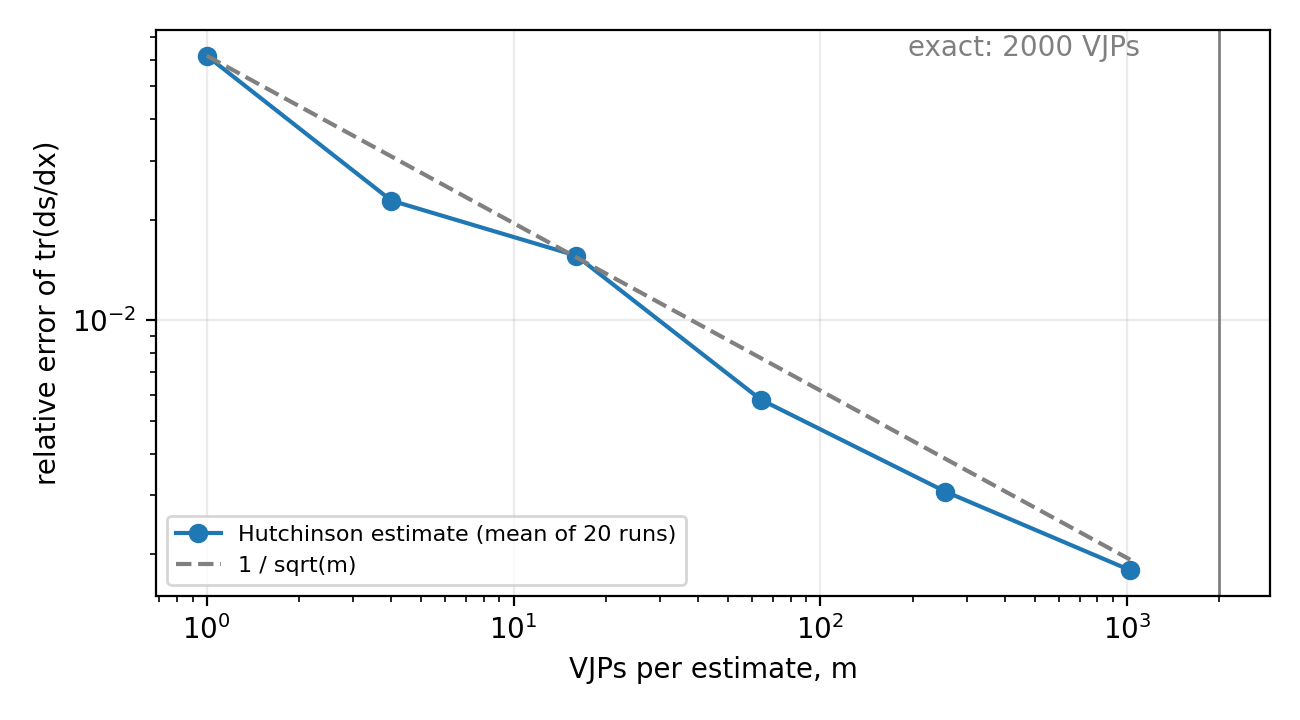

||ds/dx - W J_phi||          = 1.4e-14
||grad W - s_bar phi^T||     = 0.0e+00
||grad b - s_bar||           = 0.0e+00
exact divergence -1269.7, from 2000 VJPs
Hutchinson,    1 VJPs: relative error 6.2%
Hutchinson,   64 VJPs: relative error 0.6%
Hutchinson, 1024 VJPs: relative error 0.2%


In [ ]:
torch.manual_seed(7)
D, d = 2000, 512                                      # data dimension, feature dimension
U = torch.randn(d, D) / D**0.5
W, b = -4 * U.T, torch.randn(D)                      # like a true score: ds/dx is symmetric, <= 0
phi = lambda x: torch.tanh(U @ x)                     # feature extractor
score = lambda x: W @ phi(x) + b                      # s(x) = W phi(x) + b, Exercise 8
x = torch.randn(D)

# Exercise 8: ds/dx = W J_phi(x), and the gradients with respect to W and b
J = jacrev(score)(x)                                  # D x D, built from D VJPs
J_phi = (1 - phi(x)**2)[:, None] * U
print(f"||ds/dx - W J_phi||          = {(J - W @ J_phi).norm():.1e}")
s_bar = torch.randn(D)                                # upstream adjoint
gW, gb = grad(lambda Wb: s_bar @ (Wb[0] @ phi(x) + Wb[1]))((W, b))
print(f"||grad W - s_bar phi^T||     = {(gW - torch.outer(s_bar, phi(x))).norm():.1e}")
print(f"||grad b - s_bar||           = {(gb - s_bar).norm():.1e}")

# Divergence tr(ds/dx): exact, and Hutchinson's estimate from m VJPs with random signs
div_exact = torch.trace(J)
_, vjp_fn = vjp(score, x)
def hutchinson(m):
    v = torch.randint(0, 2, (m, D)).double() * 2 - 1    # Rademacher: E[v v^T] = I
    return torch.stack([vjp_fn(vi)[0] @ vi for vi in v]).mean()
ms = [1, 4, 16, 64, 256, 1024]
errs = []
for m in ms:
    est = torch.stack([hutchinson(m) for _ in range(20)])  # 20 repeats for the spread
    errs.append(((est - div_exact).abs() / div_exact.abs()).mean().item())
print(f"exact divergence {div_exact:.1f}, from {D} VJPs")
for m, e in zip(ms, errs):
    if m in (1, 64, 1024):
        print(f"Hutchinson, {m:4d} VJPs: relative error {e:.1%}")

plt.figure(figsize=(6.5, 3.6))
plt.loglog(ms, errs, "o-", label="Hutchinson estimate (mean of 20 runs)")
plt.loglog(ms, [errs[0] / m**0.5 for m in ms], "--", color="gray", label="1 / sqrt(m)")
plt.axvline(D, color="gray", lw=1); plt.text(D * 0.55, errs[0], f"exact: {D} VJPs", color="gray", ha="right")
plt.xlabel("VJPs per estimate, m"); plt.ylabel("relative error of tr(ds/dx)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../img/lab7_hutchinson.png", dpi=200); plt.show()

---
## Lab 8: GPTQ, Quantization Guided by the Hessian (Exercise 9)

For a linear layer, the output error of quantized weights $W_q = W + \Delta$ is $\|X\Delta\|_F^2$; per output column it is $\tfrac12 \mathbf e^\top H \mathbf e$ with $H = 2X^\top X$. Round-to-nearest ignores $H$. GPTQ quantizes one input row $q$ at a time and moves the rows not yet quantized to absorb the error, the minimizer of the quadratic:
$$\delta \mathbf w = \frac{w_q - w}{[H^{-1}]_{qq}}\, H^{-1}_{:,q}, \qquad H^{-1} \leftarrow H^{-1} - \frac{H^{-1}_{:,q} H^{-1}_{q,:}}{[H^{-1}]_{qq}}.$$
Inputs here are correlated, as real activations are, so $H$ is far from diagonal.

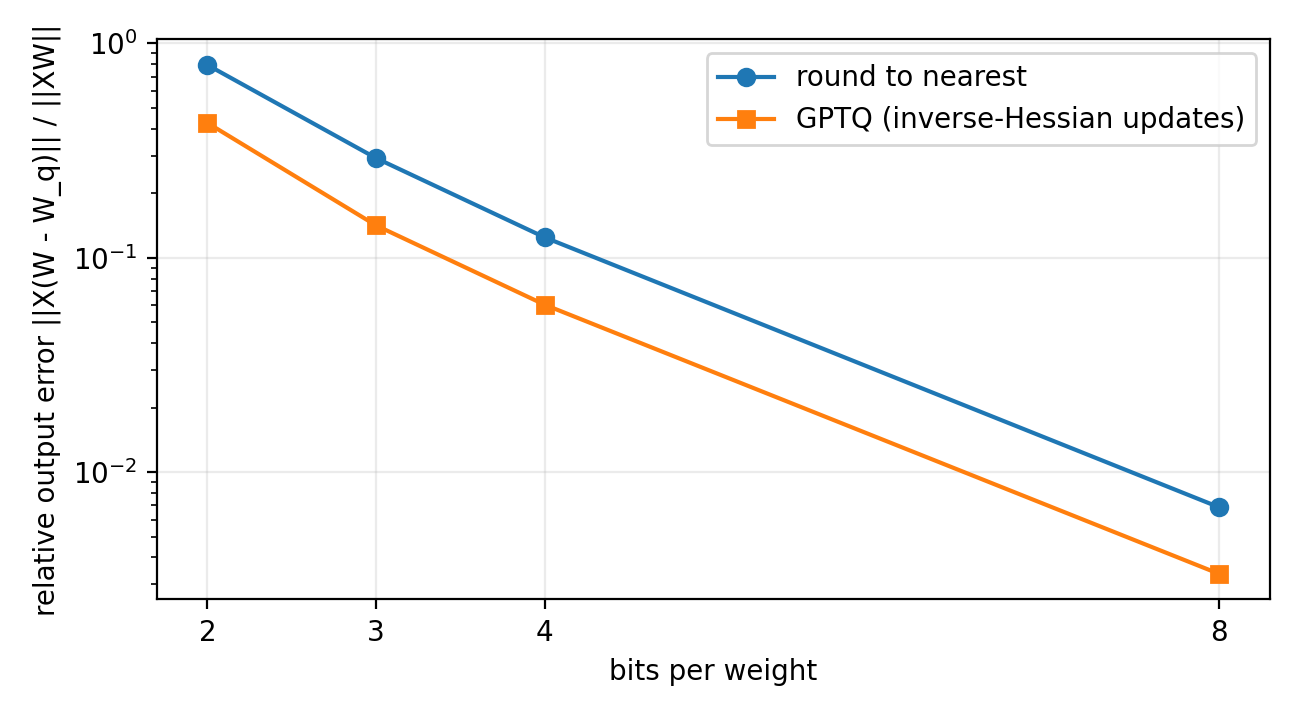

2 bits:  ||X(W - W_q)|| / ||XW||   round-to-nearest 79.40%   GPTQ 42.60%   ( 1.9x smaller)
3 bits:  ||X(W - W_q)|| / ||XW||   round-to-nearest 29.18%   GPTQ 14.17%   ( 2.1x smaller)
4 bits:  ||X(W - W_q)|| / ||XW||   round-to-nearest 12.46%   GPTQ  6.04%   ( 2.1x smaller)
8 bits:  ||X(W - W_q)|| / ||XW||   round-to-nearest  0.69%   GPTQ  0.34%   ( 2.0x smaller)


In [ ]:
torch.manual_seed(8)
N_s, d_in, m_out = 2048, 256, 128
mix = torch.randn(d_in, d_in) * torch.logspace(0, -1.5, d_in)    # correlated input features
X = torch.randn(N_s, d_in) @ mix.T
W = torch.randn(d_in, m_out) / d_in**0.5
H = 2 * X.T @ X                                       # Exercise 9: L = e^T H e / 2 per output column

def quantize(w, scale, bits):                         # symmetric grid, one scale per output column
    q = 2**(bits - 1) - 1
    return torch.clamp(torch.round(w / scale), -q, q) * scale

def rtn(W, bits):                                     # round to nearest, one row at a time, no feedback
    scale = W.abs().amax(dim=0) / (2**(bits - 1) - 1)
    return quantize(W, scale, bits)

def gptq(W, bits, damp=0.01):
    """Quantize input row q, then move the rows not yet quantized by (w_q - w) H^-1[:, q] / H^-1[q, q]."""
    W = W.clone(); Wq = torch.zeros_like(W)
    scale = W.abs().amax(dim=0) / (2**(bits - 1) - 1)
    Hd = H + damp * H.diag().mean() * torch.eye(d_in)
    Hinv = torch.linalg.inv(Hd)
    for q in range(d_in):
        Wq[q] = quantize(W[q], scale, bits)
        e = (Wq[q] - W[q]) / Hinv[q, q]
        W[q + 1:] += torch.outer(Hinv[q + 1:, q], e)  # optimal update of the remaining weights
        Hinv = Hinv - torch.outer(Hinv[:, q], Hinv[q, :]) / Hinv[q, q]   # drop row and column q
    return Wq

rel = lambda Wq: ((X @ (W - Wq)).norm() / (X @ W).norm()).item()
bits_list = [2, 3, 4, 8]
err_rtn = [rel(rtn(W, b)) for b in bits_list]
err_gptq = [rel(gptq(W, b)) for b in bits_list]
for b, r, g in zip(bits_list, err_rtn, err_gptq):
    print(f"{b} bits:  ||X(W - W_q)|| / ||XW||   round-to-nearest {r:6.2%}   GPTQ {g:6.2%}   ({r / g:4.1f}x smaller)")

plt.figure(figsize=(6.5, 3.6))
plt.semilogy(bits_list, err_rtn, "o-", label="round to nearest")
plt.semilogy(bits_list, err_gptq, "s-", label="GPTQ (inverse-Hessian updates)")
plt.xticks(bits_list); plt.xlabel("bits per weight"); plt.ylabel("relative output error ||X(W - W_q)|| / ||XW||")
plt.legend(); plt.tight_layout(); plt.savefig("../img/lab8_gptq.png", dpi=200); plt.show()

---
## Lab 9: Gradient Checking

After writing a backward pass by hand, check it against finite differences. The central difference $\frac{f(\mathbf x + h\mathbf d) - f(\mathbf x - h\mathbf d)}{2h}$ has truncation error $O(h^2)$ but subtracts two nearly equal numbers, losing digits as $h$ shrinks: the error is V-shaped in $h$. The **complex step** $\mathrm{Im}\,f(\mathbf x + ih\mathbf d)/h$ has no subtraction, so $h$ can be tiny and the error reaches machine precision.

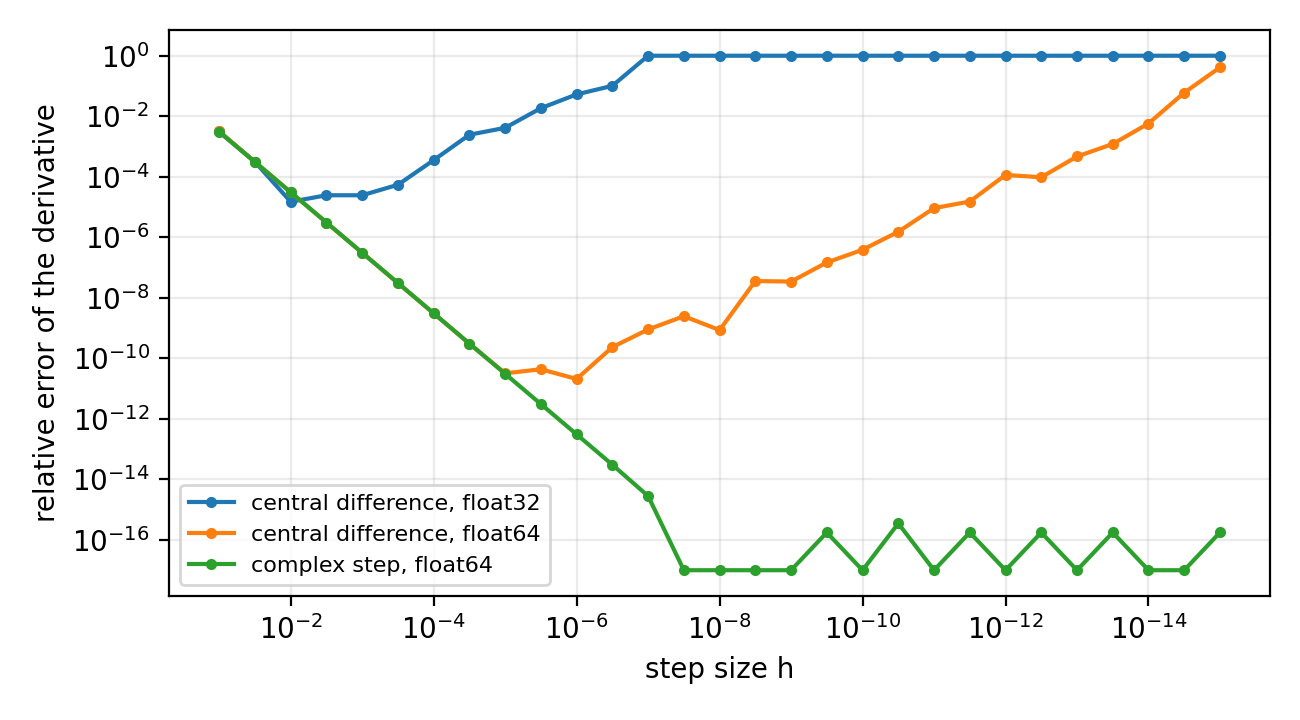

central difference, float32  best h = 1e-02   relative error 1.5e-05
central difference, float64  best h = 1e-06   relative error 2.1e-11
complex step, float64        best h = 3e-08   relative error < 1e-16


In [ ]:
torch.manual_seed(9)
n9 = 50
A9 = torch.randn(n9, n9) / n9**0.5
f9 = lambda x: torch.sum(torch.exp(torch.sin(A9.to(x.dtype) @ x)) * x**2)   # works for real and complex x
x9, d9 = torch.randn(n9), torch.randn(n9)
exact = grad(f9)(x9) @ d9                             # directional derivative from autograd

hs = torch.logspace(-1, -15, 29)
def central(dtype):                                   # (f(x + h d) - f(x - h d)) / 2h, in single or double
    x, d = x9.to(dtype), d9.to(dtype)
    return [((f9(x + h * d) - f9(x - h * d)) / (2 * h)).item() for h in hs.to(dtype)]
def complex_step():                                   # Im f(x + i h d) / h: no subtraction, no cancellation
    return [(f9(x9.to(torch.complex128) + 1j * h * d9).imag / h).item() for h in hs]

curves = {"central difference, float32": central(torch.float32),
          "central difference, float64": central(torch.float64),
          "complex step, float64": complex_step()}
for name, vals in curves.items():
    errs = [abs(v - exact.item()) / abs(exact.item()) for v in vals]
    i = int(np.argmin(errs))
    err = f"{errs[i]:.1e}" if errs[i] > 1e-16 else "< 1e-16"
    print(f"{name:28s} best h = {hs[i]:.0e}   relative error {err}")
    curves[name] = errs

plt.figure(figsize=(6.5, 3.6))
for name, errs in curves.items():
    plt.loglog(hs, [max(e, 1e-17) for e in errs], "o-", ms=3, label=name)
plt.gca().invert_xaxis()
plt.xlabel("step size h"); plt.ylabel("relative error of the derivative"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../img/lab9_gradcheck.png", dpi=200); plt.show()

---
## Lab 10: The Memory Bill of Backpropagation

Backpropagation reuses the forward activations (the chapter: "training keeps activations in memory"). **Activation checkpointing** stores only the inputs of $k$ segments and recomputes each segment's activations during the backward pass: memory falls, and each step pays roughly one extra forward pass. Measured on the GPU if there is one (peak memory needs CUDA; on a CPU only the time is reported).

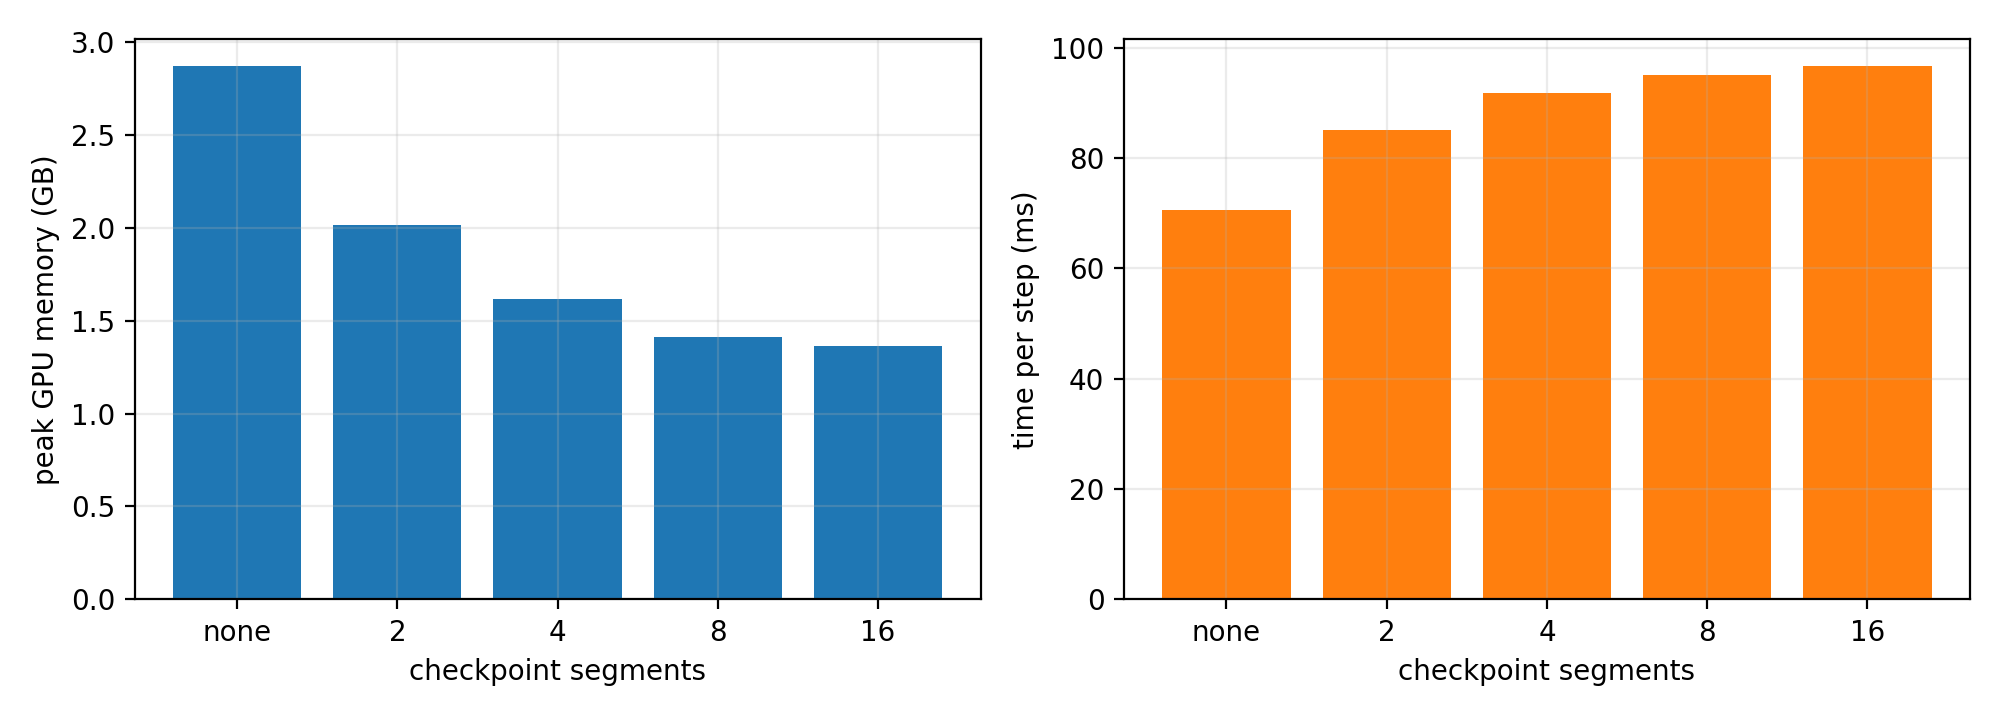

device cuda: 32 layers of 2048 x 2048, batch 4096, weights 0.54 GB
no checkpointing  peak  2.87 GB (activations 1.80 GB)   time per step   70.7 ms
 2 segments       peak  2.02 GB (activations 0.94 GB)   time per step   85.2 ms
 4 segments       peak  1.61 GB (activations 0.54 GB)   time per step   91.8 ms
 8 segments       peak  1.41 GB (activations 0.34 GB)   time per step   95.1 ms
16 segments       peak  1.36 GB (activations 0.29 GB)   time per step   96.7 ms


In [ ]:
from torch.utils.checkpoint import checkpoint_sequential
torch.manual_seed(10)
dev = "cuda" if torch.cuda.is_available() else "cpu"
depth, width, batch = 32, 2048, 4096
blocks = [torch.nn.Sequential(torch.nn.Linear(width, width), torch.nn.GELU()) for _ in range(depth)]
net = torch.nn.Sequential(*blocks).to(dev, torch.float32)
x10 = torch.randn(batch, width, device=dev, dtype=torch.float32)

def step(segments):
    """One forward and backward pass; segments = 0 keeps every activation, k keeps k of them."""
    net.zero_grad(set_to_none=True)
    out = net(x10) if segments == 0 else checkpoint_sequential(net, segments, x10, use_reentrant=False)
    out.square().mean().backward()

def measure(segments, reps=3):
    step(segments)                                    # warm-up
    if dev == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    for _ in range(reps):
        step(segments)
    if dev == "cuda":
        torch.cuda.synchronize()
    seconds_ = (time.perf_counter() - t0) / reps
    peak = torch.cuda.max_memory_allocated() / 1e9 if dev == "cuda" else float("nan")
    return peak, seconds_

weights_gb = sum(p.numel() for p in net.parameters()) * 4 / 1e9
print(f"device {dev}: {depth} layers of {width} x {width}, batch {batch}, weights {weights_gb:.2f} GB")
results = {}
for seg in [0, 2, 4, 8, 16]:
    peak, sec = measure(seg)
    results[seg] = (peak, sec)
    label = "no checkpointing" if seg == 0 else f"{seg:2d} segments"
    acts = peak - 2 * weights_gb                      # minus the weights and their gradients
    print(f"{label:17s} peak {peak:5.2f} GB (activations {acts:4.2f} GB)   time per step {1e3 * sec:6.1f} ms")

segs = list(results)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
names = ["none" if s == 0 else str(s) for s in segs]
axes[0].bar(names, [results[s][0] for s in segs], color="tab:blue")
axes[0].set_xlabel("checkpoint segments"); axes[0].set_ylabel("peak GPU memory (GB)")
axes[1].bar(names, [1e3 * results[s][1] for s in segs], color="tab:orange")
axes[1].set_xlabel("checkpoint segments"); axes[1].set_ylabel("time per step (ms)")
plt.tight_layout(); plt.savefig("../img/lab10_checkpointing.png", dpi=200); plt.show()